In [16]:
import math
import torch
import matplotlib.pyplot as plt
import numpy as np
from freqsde import VEConvMixSDE   # adjust to your filename
from hydra.core.hydra_config import HydraConfig
from hydra.utils import instantiate, to_absolute_path
DEVICE =  'cpu'
print('device:', DEVICE)

device: cpu


In [17]:
K     = 2
T     = 1.0
N     = 100
alpha = 1.
beta  = 1.
sde = VEConvMixSDE(
    feature_dim      = K,
    drift_decay_rate    = alpha,
    zero_mode_decay_rate      = beta,
    sigma_min = 0.1,
    sigma_max = 0.2,
    steps     = 10000,
    terminal_time        = T,
    num_reverse_steps       = N,
)

In [18]:
filters_path = "/gpfs/data/ssa/users/d634375/FourierDiffusionConvolutiveSourceSeparation/data/sim_2src/filters/filters.npy"
arr = np.load(filters_path, allow_pickle=True)

max_length = max(len(x) for x in arr)
# N is the total signal length for FFT
N = 2000 + max_length - 1
num_fft_bins = N // 2 + 1

kernels = torch.stack(
    [torch.fft.rfft(torch.tensor(x, dtype=torch.float32), n=N) for x in arr]
)
sde.get_mix_mat(kernels, num_fft_bins)

VEConvMixSDE(T=1.0, N=100)

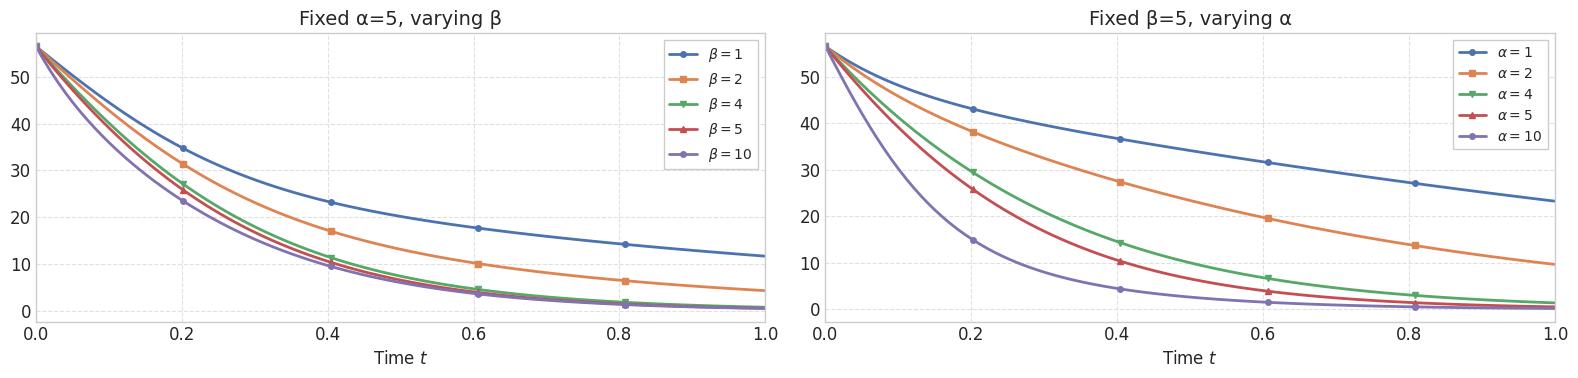

In [20]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ================================================================
# Plot style — identical to reference script
# ================================================================
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]
STYLE  = "seaborn-v0_8-whitegrid"

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "font.size":         14,
    "axes.titlesize":    14,
    "axes.labelsize":    12,
    "xtick.labelsize":   12,
    "ytick.labelsize":   12,
    "legend.fontsize":   12,
    "lines.linewidth":   2,
    "axes.spines.top":   True,
    "axes.spines.right": True,
    "axes.grid":         True,
    "grid.color":        "#e0e0e0",
    "grid.linewidth":    0.8,
    "grid.linestyle":    "--",
    "axes.axisbelow":    True,
})

# ================================================================
# Sweep parameters
# ================================================================
T             = torch.linspace(0.0, 1.0, 100)
fixed_alpha   = 5
fixed_beta    = 5
beta_values   = [1, 2, 4, 5, 10]
alpha_values  = [1, 2, 4, 5, 10]
markers       = ['o', 's', 'v', '^']

# ================================================================
# Figure
# ================================================================
with plt.style.context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4))

    # ----------------------------------------------------------
    # Left panel: fix alpha, vary beta
    # ----------------------------------------------------------
    for i, beta in enumerate(beta_values):
        sde.drift_decay_rate      = fixed_alpha
        sde.zero_mode_decay_rate  = beta
        Ft     = sde.get_exp_Ft_integral(T)
        errors = torch.linalg.norm(Ft - sde.A, dim=(1, 2))

        axes[0].plot(
            T.cpu().numpy(),
            errors.cpu().numpy(),
            label     = f"$\\beta={beta}$",
            color     = COLORS[i % len(COLORS)],
            marker    = markers[i % len(markers)],
            markevery = 20,
            linewidth = 2,
            markersize= 4,
        )
    axes[0].set_title(f"Fixed α={fixed_alpha}, varying β")
    axes[0].set_xlabel("Time $t$")
    axes[0].margins(x=0)

    # No tick marks, keep tick labels
    axes[0].tick_params(axis="both", which="both", length=0)

    axes[0].yaxis.grid(True, which="major", color="#e0e0e0", linewidth=0.8, linestyle="--")
    axes[0].xaxis.grid(True, which="major", color="#e0e0e0", linewidth=0.8, linestyle="--")
    axes[0].legend(
        fontsize   = 10,
        ncol       = 1,
        framealpha = 1,
        edgecolor  = "#cccccc",
        fancybox   = False,
        frameon    = True,
    )

    # ----------------------------------------------------------
    # Right panel: fix beta, vary alpha
    # ----------------------------------------------------------
    for i, alpha in enumerate(alpha_values):
        sde.drift_decay_rate      = alpha
        sde.zero_mode_decay_rate  = fixed_beta
        Ft     = sde.get_exp_Ft_integral(T)
        errors = torch.linalg.norm(Ft - sde.A, dim=(1, 2))

        axes[1].plot(
            T.cpu().numpy(),
            errors.cpu().numpy(),
            label     = f"$\\alpha={alpha}$",
            color     = COLORS[i % len(COLORS)],
            marker    = markers[i % len(markers)],
            markevery = 20,
            linewidth = 2,
            markersize= 4,
        )
    axes[1].set_title(f"Fixed β={fixed_beta}, varying α")
    axes[1].set_xlabel("Time $t$")
    axes[1].margins(x=0)

    # No tick marks, keep tick labels
    axes[1].tick_params(axis="both", which="both", length=0)

    axes[1].yaxis.grid(True, which="major", color="#e0e0e0", linewidth=0.8, linestyle="--")
    axes[1].xaxis.grid(True, which="major", color="#e0e0e0", linewidth=0.8, linestyle="--")
    axes[1].legend(
        fontsize   = 10,
        ncol       = 1,
        framealpha = 1,
        edgecolor  = "#cccccc",
        fancybox   = False,
        frameon    = True,
    )

    plt.tight_layout()
    plt.savefig("alpha_beta_analytic.pdf", dpi=300, bbox_inches="tight")
    plt.show()

In [21]:
sde.eigenvalues, sde.eigenvector_matrix = torch.linalg.eig(sde.A)
sde.inv_eigenvector_matrix = torch.linalg.inv(sde.eigenvector_matrix)

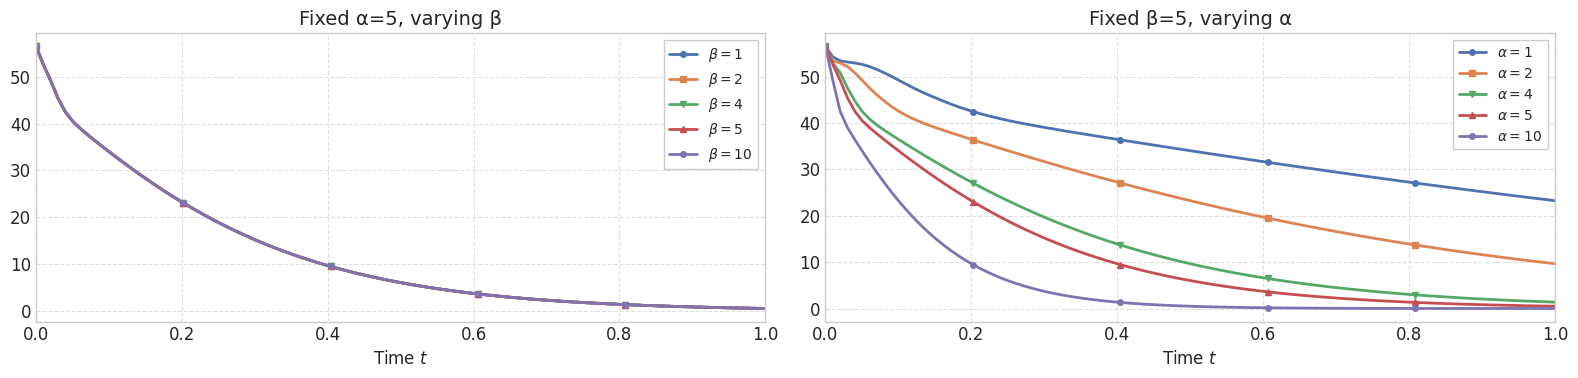

In [22]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ================================================================
# Plot style — identical to reference script
# ================================================================
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]
STYLE  = "seaborn-v0_8-whitegrid"

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "font.size":         14,
    "axes.titlesize":    14,
    "axes.labelsize":    12,
    "xtick.labelsize":   12,
    "ytick.labelsize":   12,
    "legend.fontsize":   12,
    "lines.linewidth":   2,
    "axes.spines.top":   True,
    "axes.spines.right": True,
    "axes.grid":         True,
    "grid.color":        "#e0e0e0",
    "grid.linewidth":    0.8,
    "grid.linestyle":    "--",
    "axes.axisbelow":    True,
})

# ================================================================
# Sweep parameters
# ================================================================
T             = torch.linspace(0.0, 1.0, 100)
fixed_alpha   = 5
fixed_beta    = 5
beta_values   = [1, 2, 4, 5, 10]
alpha_values  = [1, 2, 4, 5, 10]
markers       = ['o', 's', 'v', '^']

# ================================================================
# Figure
# ================================================================
with plt.style.context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4))

    # ----------------------------------------------------------
    # Left panel: fix alpha, vary beta
    # ----------------------------------------------------------
    for i, beta in enumerate(beta_values):
        sde.drift_decay_rate      = fixed_alpha
        sde.zero_mode_decay_rate  = beta
        Ft     = sde.get_exp_Ft_integral(T)
        errors = torch.linalg.norm(Ft - sde.A, dim=(1, 2))

        axes[0].plot(
            T.cpu().numpy(),
            errors.cpu().numpy(),
            label     = f"$\\beta={beta}$",
            color     = COLORS[i % len(COLORS)],
            marker    = markers[i % len(markers)],
            markevery = 20,
            linewidth = 2,
            markersize= 4,
        )
    axes[0].set_title(f"Fixed α={fixed_alpha}, varying β")
    axes[0].set_xlabel("Time $t$")
    axes[0].margins(x=0)

    # No tick marks, keep tick labels
    axes[0].tick_params(axis="both", which="both", length=0)

    axes[0].yaxis.grid(True, which="major", color="#e0e0e0", linewidth=0.8, linestyle="--")
    axes[0].xaxis.grid(True, which="major", color="#e0e0e0", linewidth=0.8, linestyle="--")
    axes[0].legend(
        fontsize   = 10,
        ncol       = 1,
        framealpha = 1,
        edgecolor  = "#cccccc",
        fancybox   = False,
        frameon    = True,
    )

    # ----------------------------------------------------------
    # Right panel: fix beta, vary alpha
    # ----------------------------------------------------------
    for i, alpha in enumerate(alpha_values):
        sde.drift_decay_rate      = alpha
        sde.zero_mode_decay_rate  = fixed_beta
        Ft     = sde.get_exp_Ft_integral(T)
        errors = torch.linalg.norm(Ft - sde.A, dim=(1, 2))

        axes[1].plot(
            T.cpu().numpy(),
            errors.cpu().numpy(),
            label     = f"$\\alpha={alpha}$",
            color     = COLORS[i % len(COLORS)],
            marker    = markers[i % len(markers)],
            markevery = 20,
            linewidth = 2,
            markersize= 4,
        )
    axes[1].set_title(f"Fixed β={fixed_beta}, varying α")
    axes[1].set_xlabel("Time $t$")
    axes[1].margins(x=0)

    # No tick marks, keep tick labels
    axes[1].tick_params(axis="both", which="both", length=0)

    axes[1].yaxis.grid(True, which="major", color="#e0e0e0", linewidth=0.8, linestyle="--")
    axes[1].xaxis.grid(True, which="major", color="#e0e0e0", linewidth=0.8, linestyle="--")
    axes[1].legend(
        fontsize   = 10,
        ncol       = 1,
        framealpha = 1,
        edgecolor  = "#cccccc",
        fancybox   = False,
        frameon    = True,
    )

    plt.tight_layout()
    plt.savefig("alpha_beta_torch.pdf", dpi=300, bbox_inches="tight")
    plt.show()